### Valentin Lorenzo Carroza Granifo 22.437.518-2

In [39]:
import numpy as np # Importa la biblioteca numpy al codigo
import matplotlib.pyplot as plt # importa la biblioteca matplotlib al codigo

In [40]:
rng = np.random.default_rng(seed=1489)

### Problema 1

In [41]:
años = np.linspace(0,10, 500) # Crea 500 puntos equidistantes en 10 años.

In [42]:
flujo = np.ones_like(años) # Crea un arreglo lleno de 1 en todos los tiempos.

In [43]:
flujo = flujo + rng.normal(loc=0.0, scale=0.002, size=años.size) # Agrega el ruido de gauss a todos los tiempos.

In [44]:
mascara1 = (años >= 4.5) & (años <= 5.0) # Mascara para el primer tránsito (4.5 a 5.0 años)
flujo[mascara1] -= 0.02

In [45]:
mascara2 = (años >= 7.0) & (años <= 7.4) # Mascara para el segundo transito (7.0 a 7.4 años)
flujo[mascara2] -= 0.015

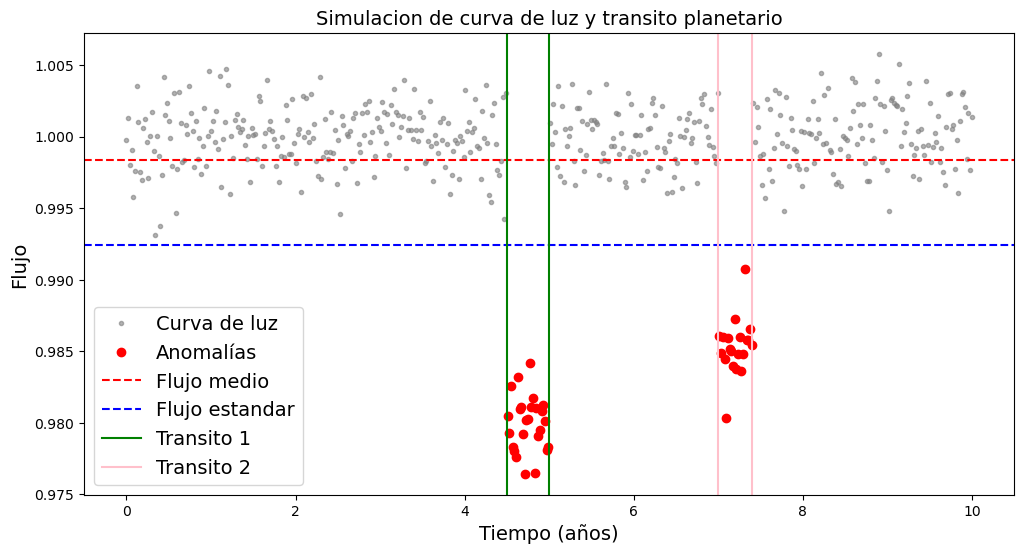

In [46]:
def grafica_luz(tiempo, flujo):
    '''
    Calcula la grafica de luz del flujo.

    Parameters
    ----------
    tiempo: numpy.ndarray
        Arreglo que contiene los tiempos del transito en años.
    flujo: numpy.ndarray
        Arreglo que contiene los valores del flujo.
    
    Returns
    -------
    None
        La función no retorna ningún valor, imprime la grafica.
    '''
    f_medio = np.mean(flujo) # Calcula el promedio del arreglo del flujo.
    f_standar = 0.002 # Calcula la desviacion estandar del flujo.
    umbral = f_medio - 3*f_standar # Calcula el umbral de deteccion del transito.
    transito = flujo < umbral # Calculo los puntos donde ocurre un transito.
    plt.figure(figsize=(12,6)) # Determina el tamaño de la figura.
    plt.plot(tiempo, flujo, '.', color='gray', alpha=0.6, label='Curva de luz') # Grafica todos los puntos de la curva de luz.
    plt.plot(tiempo[transito], flujo[transito], 'ro', label=r'Anomalías') # Grafica los puntos en que ocurre el transito.
    plt.axhline(f_medio,  color='red', linestyle='--', label='Flujo medio') # linea horizontal que muestra el flujo medio.
    plt.axhline(umbral, linestyle='--', color='blue', label='Flujo estandar') # Linea horizontal que muestra la desviacion estandar.
    plt.axvline(4.5, color='green', label='Transito 1') # Linea vertical que limita el comienzo del 1° transito.
    plt.axvline(5.0, color='green') # Linea vertical que limita el final del 1° transito.
    plt.axvline(7.0, color='pink', label='Transito 2') # Linea vertical que limita el comienzo del 2° transito.
    plt.axvline(7.4, color='pink') # Linea vertical que limita el final del 2° transito.
    plt.xlabel('Tiempo (años)', fontsize=14) # leyenda del eje x.
    plt.ylabel('Flujo', fontsize=14) # leyenda del eje y.
    plt.title('Simulacion de curva de luz y transito planetario', fontsize=14) # Titulo del grafico.
    plt.legend(fontsize=14) # Tamaño de la leyenda.


grafica_luz(años, flujo)

### Problema 2

In [47]:
Nestrellas = 5 # Cantidad de estrellas.
I0 = 100 # Intentsidad maxima emitida.
sigma = 0.5 # Dispercion espacial
x0 = rng.uniform(-5, 5, Nestrellas) # Define posiciones aleatorias para las 5 estrellas entre -5 y 5
y0 = rng.uniform(-5, 5, Nestrellas) # Define posiciones aleatorias para las 5 estrellas entre -5 y 5

In [48]:
x = np.linspace(-5, 5, 100) # Crea 100 puntos equidistantes en x.
y = np.linspace(-5, 5, 100) # Crea 100 puntos equidistantes en y.
X_grilla, Y_grilla = np.meshgrid(x,y) # Crea las matrices de cordenadas.

In [49]:
imagen_astronomica = np.zeros_like(X_grilla) # Crea una matriz de de ceros para rellenar con las intensidades.

In [50]:
for i in range(Nestrellas): # Evalúa la intensidad de la I0 estrella en cada píxel.
    gaussiana_estrella = I0 * np.exp(-((X_grilla - x0[i])**2 + (Y_grilla - y0[i])**2) / (2 * sigma**2)) 
    imagen_astronomica += gaussiana_estrella # Acumula las intensidades en la matriz.

Text(0.5, 1.0, 'Imagen Simulado 5 estrellas')

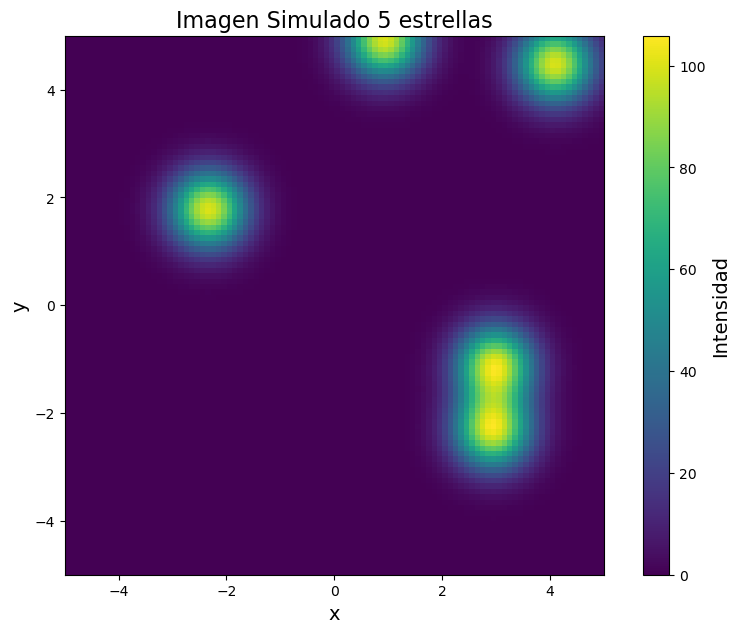

In [51]:
plt.figure(figsize=(10, 7)) # Define el tamaño del grafico.
im = plt.imshow(imagen_astronomica, extent=[-5, 5, -5, 5]) # Visualiza la matriz 2d con los ejes de -5 a 5 en x e y.
cbar = plt.colorbar(im) # Crea la barra de colores.
cbar.set_label('Intensidad', fontsize=14) # Imprime la barra de colores con un tamaño y titulo. 
plt.xlabel('x', fontsize=14) # Nombre el eje x.
plt.ylabel('y', fontsize=14) # Nombra el eje y.
plt.title('Imagen Simulado 5 estrellas', fontsize=16) # Asigna un titulo al grafico.

In [52]:
def calculo_dist_euc(x0,y0):
    '''
    Calcula las distancias euclidianas entre los centros de todas las estrellas.

    Parameters
    ----------
    x0 : numpy.ndarray
        Arreglo con las posiciones en x de las estrellas.
    y0 : numpy.ndarray
        Arreglo con las posiciones en y de las estrellas.
    Returns
    -------
        distancias : numpy.ndarray
            Matriz simétrica de N x N donde el elemento (i, j) representa la distancia entre la estrella i y la estrella j. 
    '''
    n = len(x0)
    distancias = np.zeros((n, n))
    
    for i in range(n):
        for j in range(n):
            distancias[i, j] = np.sqrt((x0[i] - x0[j])**2 + (y0[i] - y0[j])**2)
            
    return distancias

In [53]:
matriz_distancias = calculo_dist_euc(x0, y0) # Llama a la funcion usando los datos de las estrellas.

In [54]:
print(np.round(matriz_distancias, 3)) # Imprime la matriz de las distancias.

[[0.    7.041 4.579 6.741 6.105]
 [7.041 0.    3.228 6.959 5.747]
 [4.579 3.228 0.    7.59  6.432]
 [6.741 6.959 7.59  0.    1.225]
 [6.105 5.747 6.432 1.225 0.   ]]


In [55]:
intensidades = [] # Crea una lista vacia de intesidades.
for i in range(Nestrellas):
    gaussiana_individual = I0 * np.exp(-((X_grilla - x0[i])**2 + (Y_grilla - y0[i])**2) / (2 * sigma**2))
    intensidades.append(np.max(gaussiana_individual))

In [56]:
indices_ordenados = np.argsort(intensidades) # Muestra los indices de las intensidades de menor a mayor.

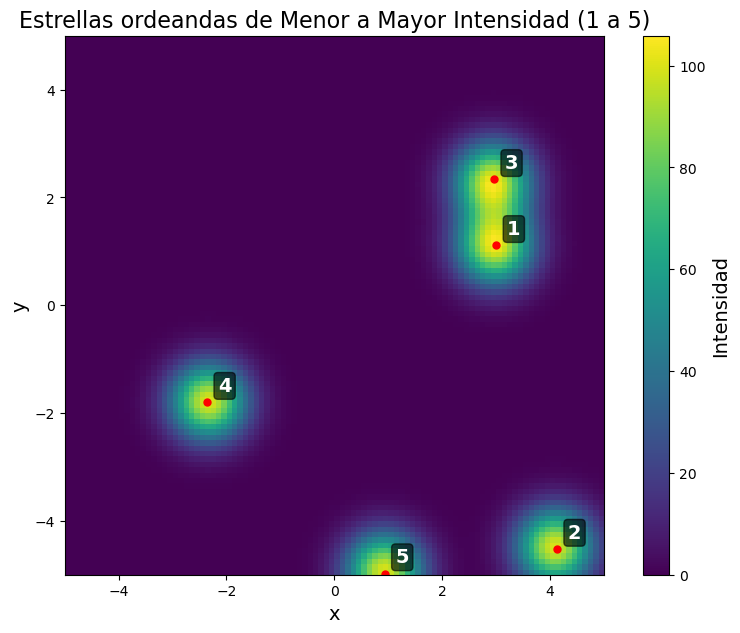

In [57]:
plt.figure(figsize=(10, 7)) # Grafica la imagen con las marcas y numeros.
im = plt.imshow(imagen_astronomica,origin='lower',extent=[-5, 5, -5, 5])
for numero_orden, idx_original in enumerate(indices_ordenados, start=1):
    x_pos = x0[idx_original]
    y_pos = y0[idx_original]
    
    plt.plot(x_pos, y_pos, 'ro', markersize=5)
    plt.text(x_pos + 0.2, y_pos + 0.2, str(numero_orden), color='white', 
             fontsize=14, fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.2', facecolor='black', alpha=0.6))
cbar = plt.colorbar(im)
cbar.set_label('Intensidad', fontsize=14)
plt.xlabel('x', fontsize=14)
plt.ylabel('y', fontsize=14)
plt.title('Estrellas ordeandas de Menor a Mayor Intensidad (1 a 5)', fontsize=16)
plt.grid(False)

In [58]:
sigmas = [0.25, 0.5, 0.75, 1.0]

Text(0.5, 0.98, 'Efecto de la variacion de sigma en las estrellas')

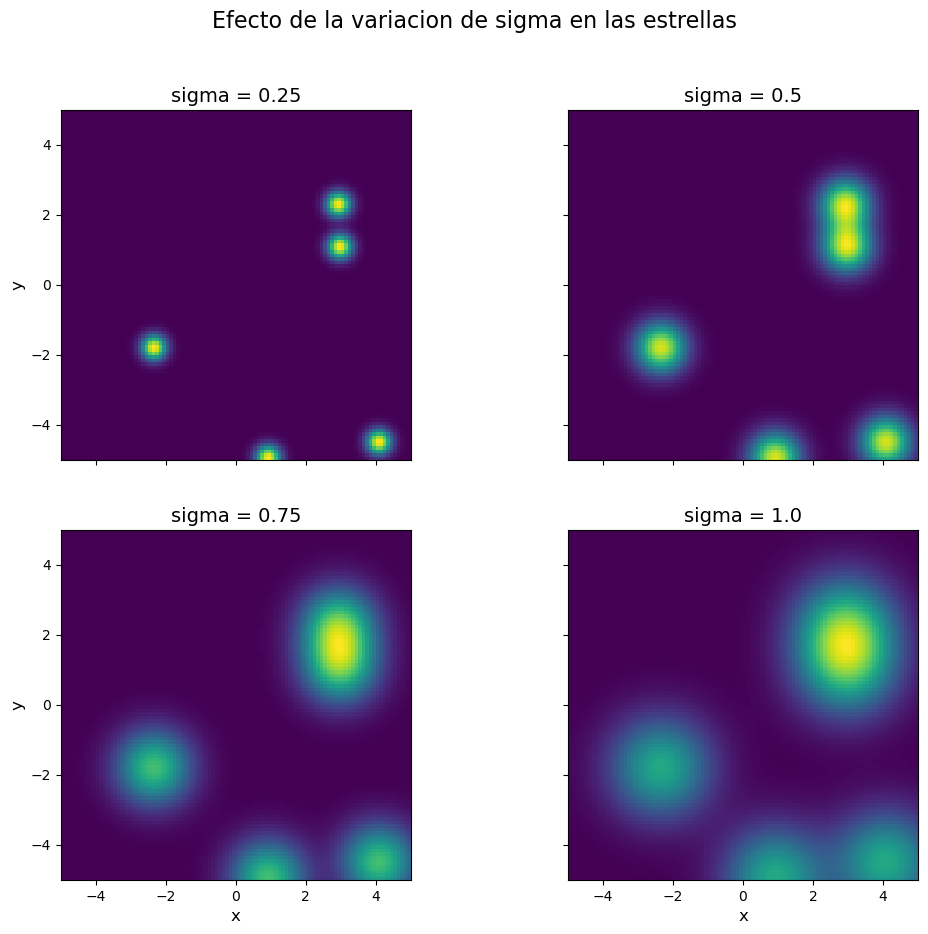

In [59]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True) # Crear la figura 2x2 compartiendo ejes x e y.
axes_flatt = axes.flatten() # Aplana la matriz de subplots.
im_last = None # Guarda la imagen para la barra de color.
for idx, sig in enumerate(sigmas):
    imagen_sigma = np.zeros_like(X_grilla) # Reconstruye la matriz de la imagen usando el sigma actual.
    for i in range(Nestrellas):
        gaussiana = I0 * np.exp(-((X_grilla - x0[i])**2 + (Y_grilla - y0[i])**2) / (2 * sig**2))
        imagen_sigma += gaussiana

    ax = axes_flatt[idx]
    
    # Graficar la imagen en el subplot correspondiente sin símbolos LaTeX
    ax.set_title(f'sigma = {sig}', fontsize=14)
    im_last = ax.imshow(imagen_sigma, origin='lower', extent=[-5, 5, -5, 5], cmap='viridis') 
    ax.grid(False)

# Configura etiquetas compartidas en los bordes exteriores
for ax in axes[1, :]:
    ax.set_xlabel('x', fontsize=12)
for ax in axes[:, 0]:
    ax.set_ylabel('y', fontsize=12)
fig.suptitle('Efecto de la variacion de sigma en las estrellas', fontsize=16, y=0.98)
